In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

In [2]:
df = pd.read_csv("combined_weekly_data.csv", index_col=0)
df

,oil_ret,inv_chg,fp_chg,vix_ret
date,,,,
1990-01-12,0.004335,0.011094,0.000000,0.225261
1990-01-19,0.022874,-0.005021,0.000000,-0.086851
1990-01-26,-0.048101,-0.006285,0.000000,0.168000
1990-02-02,0.021277,0.030868,-0.015043,-0.074581
1990-02-09,-0.052951,-0.014402,0.000000,-0.025905
...,...,...,...,...
2026-09-11,0.092567,-0.001509,-0.000215,0.090158
2026-09-18,0.001679,0.007012,-0.000359,-0.065025
2026-09-25,-0.159799,0.002162,0.001148,0.004051


In [3]:
def test_stationarity(series):
    result = adfuller(series.dropna(), autolag="AIC")

    print("ADF statistic:", result[0])
    print("p-value:", result[1])
    print("Critical values:", result[4])

test_stationarity(df["oil_ret"])

ADF statistic: -13.438388851225849
p-value: 3.88873431052521e-25
Critical values: {'1%': np.float64(-3.4337855345177255), '5%': np.float64(-2.863057593089076), '10%': np.float64(-2.56757790858712)}


/var/folders/7d/swc7580d3fz3852zc_1h_1pw0000gn/T/ipykernel_43188/4058520252.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna(), autolag="AIC")


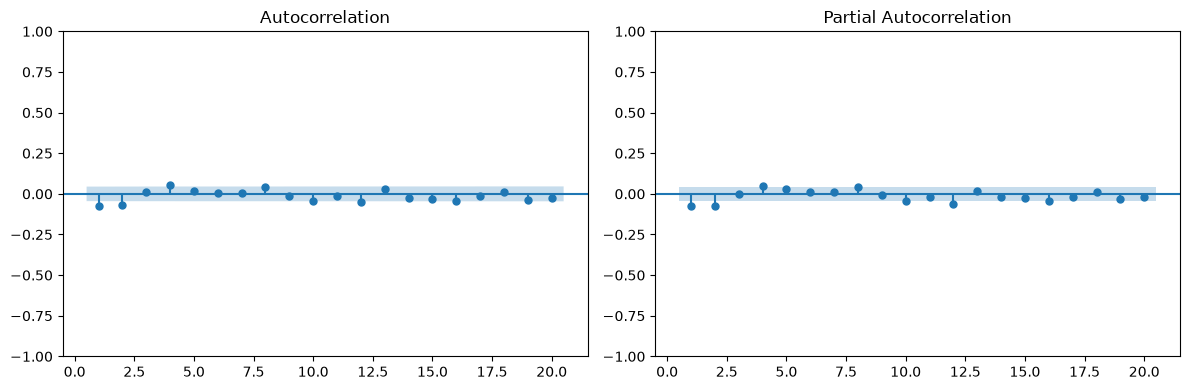

In [4]:
returns = df["oil_ret"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(returns, lags=20, zero=False, ax=axes[0])
plot_pacf(returns, lags=20, zero=False, ax=axes[1])

plt.tight_layout()
plt.show()

In [5]:
y = df["oil_ret"]
X = sm.add_constant(df[["inv_chg", "fp_chg", "vix_ret"]])

# HAC standard errors allow for heteroskedasticity
# and short-range autocorrelation
model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 4}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                oil_ret   R-squared:                       0.019
Model:                            OLS   Adj. R-squared:                  0.017
Method:                 Least Squares   F-statistic:                     5.068
Date:                Wed, 28 Oct 2026   Prob (F-statistic):            0.00169
Time:                        23:46:14   Log-Likelihood:                 2750.3
No. Observations:                1918   AIC:                            -5493.
Df Residuals:                    1914   BIC:                            -5470.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0030      0.001      2.511      0.0

In [6]:
features = pd.DataFrame({
    "inv_chg": df["inv_chg"].shift(1),
    "fp_chg": df["fp_chg"].shift(1),
    "vix_ret": df["vix_ret"],
})
target = df["oil_ret"].shift(-1)

model_data = pd.concat([target.rename("next_oil_ret"), features], axis=1).dropna()
y = model_data["next_oil_ret"]
X = sm.add_constant(model_data[["inv_chg", "fp_chg", "vix_ret"]])

# HAC standard errors allow for heteroskedasticity
# and short-range autocorrelation
model = sm.OLS(y, X).fit(
    cov_type="HAC",
    cov_kwds={"maxlags": 4}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           next_oil_ret   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     1.146
Date:                Wed, 28 Oct 2026   Prob (F-statistic):              0.329
Time:                        23:52:32   Log-Likelihood:                 2729.9
No. Observations:                1916   AIC:                            -5452.
Df Residuals:                    1912   BIC:                            -5430.
Df Model:                           3                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0025      0.001      2.121      0.0